#    1.Введение
   
Гибель «Титаника», одного из самых печально известных кораблекрушений в истории, произошедшая после столкновения с ледником 5 апреля 1912 года во время своего первого плавания. К сожалению, спасательных шлюпок на борту оказалось недостаточно, что привело к гибели 1502 из 2224 пассажиров и членов экипажа. Хотя в выживании присутствует элемент удачи, похоже, что у некоторых людей больше шансов выжить, чем у других. В этом анализе данных нам необходимо использовать данные о пассажирах (имя, возраст, стоимость проезда и т. д.) для построения прогностической модели, которая ответит на вопрос: «Какие люди имеют больше шансов выжить?»

In [10]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
#pd.set_option('display.max_rows', None)      # Выводить ВСЕ строки (без многоточий)
#pd.set_option('display.max_colwidth', 100)
#pd.set_option('display.max_columns', None)   # Выводить ВСЕ столбцы
#pd.set_option('display.width', 1000)         # Ширина экрана для вывода (чтобы строки не переносились)

In [72]:
train_data = pd.read_csv("Hm5_titanic.csv")
train_data.head(140)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.00,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.00,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.00,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.00,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.00,1,0,237736,30.0708,NaN,C


#  1. Проанализируйте уровень выживаемости в каждом классе каюты

Здравый смысл подсказывает, что чем выше уровень каюты, чем ближе она к палубе, тем легче выбраться в случае кораблекрушения. Рассмотрим это:

According to the bar chart, we can see that the cabin class has a great relationship with the survival rate. The survival rate of the first-class cabin is much higher than that of other cabins, reaching more than 60%, almost three times that of the third-class cabin.

In [18]:
#ваш код...
cl = train_data.groupby('Pclass')['Survived'].mean()
print(cl)

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


# **2. Показатели выживаемости были проанализированы для каждого пола**

Учитывая различия в физических возможностях мужчин и женщин, проанализировать коэффициент выживаемости в связке с полом. Вычислить долю выживших мужчин и женщин, провести группировку по признакам.

In [19]:
#ваш код
s = train_data.groupby('Sex')['Survived'].mean()
print(s)

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


# **3. Анализ связи между возрастом, полом и уровнем выживаемости**

PС: у женщин были другие возрастные группы когда парни к 30 годам женились, 
незамужние девушки уже в 25 считались старой девой. для удобства буду смотреть
одинаковые возрастные разбиения


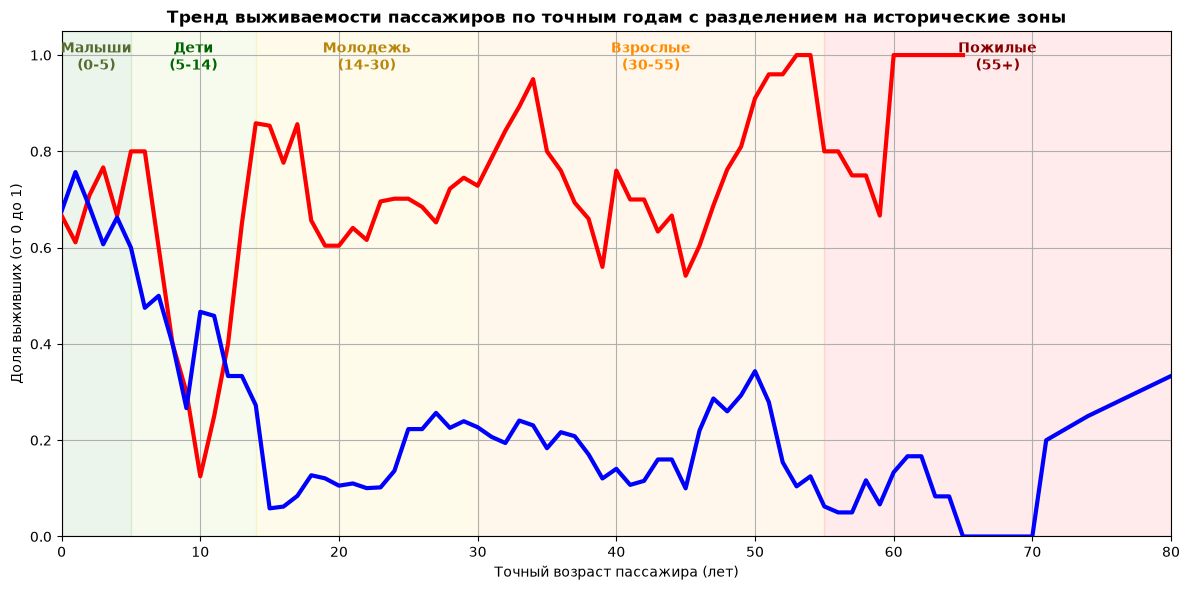

In [59]:
age_bins = range(0, 81)
age_survival = train_data.groupby(['AgeRound', 'Sex'], observed=False)['Survived'].mean().unstack()
survival_mtrx_smoothed = age_survival.rolling(window=5, min_periods=1, center=True).mean()
fig, ax = plt.subplots(figsize=(12, 6))
#фигура, холст
# Рисуем линии. .index теперь гарантированно состоит из ЧИСЕЛ (лет), ошибка ушла
ax.plot(survival_mtrx_smoothed.index, survival_mtrx_smoothed['female'], color='red', label='Женщины', linewidth=3, zorder=5)
ax.plot(survival_mtrx_smoothed.index, survival_mtrx_smoothed['male'], color='blue', label='Мужчины', linewidth=3, zorder=5)

#заливаю фон
ax.axvspan(0, 5, color='green', alpha=0.08)
ax.axvspan(5, 14, color='yellowgreen', alpha=0.08)
ax.axvspan(14, 30, color='gold', alpha=0.08)
ax.axvspan(30, 55, color='orange', alpha=0.08)
ax.axvspan(55, 80, color='red', alpha=0.08)


#подписываем зоны
y = 0.97
ax.text(2.5, y, 'Малыши\n(0-5)', horizontalalignment='center',  fontweight='bold', color='darkolivegreen')
ax.text(9.5, y, 'Дети\n(5-14)', horizontalalignment='center', fontweight='bold', color='darkgreen')
ax.text(22, y, 'Молодежь\n(14-30)', horizontalalignment='center', fontweight='bold', color='darkgoldenrod')
ax.text(42.5,y, 'Взрослые\n(30-55)', horizontalalignment='center', fontweight='bold', color='darkorange')
ax.text(67.5, y, 'Пожилые\n(55+)', horizontalalignment='center', fontweight='bold', color='darkred')

ax.set_title('Тренд выживаемости пассажиров по точным годам с разделением на исторические зоны',fontweight='bold')
ax.set_xlabel('Точный возраст пассажира (лет)')
ax.set_ylabel('Доля выживших (от 0 до 1)')

ax.set_xlim(0, 80)    # Ограничение по возрасту строго до 80 лет
ax.set_ylim(0, 1.05)  # Шкала выживаемости от 0 до 100%

ax.grid()

# Выводим текстовые комментарии, которые у тебя были в конце ячейки
print('PС: у женщин были другие возрастные группы когда парни к 30 годам женились, ')
print('незамужние девушки уже в 25 считались старой девой. для удобства буду смотреть')
print('одинаковые возрастные разбиения')

plt.tight_layout()
plt.show()

In [77]:
girls_10 = train_data[(train_data['Sex'] == 'female') & (train_data['Age'] >= 8) & (train_data['Age'] <= 12)]
print('Girls 8-12', '\n', girls_10[['Name', 'Age', 'Pclass', 'Survived']], '\n')

old_men = train_data[(train_data['Sex'] == 'male') & (train_data['Age'] >= 62) & (train_data['Age'] <= 70)]
print('Old men 62-70', '\n', old_men[['Name', 'Age', 'Pclass', 'Survived']])

Girls 8-12 
                                      Name   Age  Pclass  Survived
24          Palsson, Miss. Torborg Danira   8.0       3         0
147      Ford, Miss. Robina Maggie "Ruby"   9.0       3         0
237      Collyer, Miss. Marjorie "Lottie"   8.0       2         1
419             Van Impe, Miss. Catharina  10.0       3         0
541  Andersson, Miss. Ingeborg Constanzia   9.0       3         0
542     Andersson, Miss. Sigrid Elisabeth  11.0       3         0
634                    Skoog, Miss. Mabel   9.0       3         0
852               Boulos, Miss. Nourelain   9.0       3         0 

Old men 62-70 
                                Name   Age  Pclass  Survived
33            Wheadon, Mr. Edward H  66.0       2         0
54   Ostby, Mr. Engelhart Cornelius  65.0       1         0
252       Stead, Mr. William Thomas  62.0       1         0
280                Duane, Mr. Frank  65.0       3         0
438               Fortune, Mr. Mark  64.0       1         0
456       Mille

Провести анализ прочих факторов, в зависимости от вашего выбора.

In [83]:
train_data['Age_Nan'] = train_data['Age'].isna()
print('Выживаемость в зависимости от наличия возраста:')
print(train_data.groupby('Age_Nan')['Survived'].mean(), '\n')

print('В каком классе ехали люди без возраста:')
print(train_data[train_data['Age_Nan'] == True]['Pclass'].value_counts(), '\n')

print(train_data.groupby(['Age_Nan', 'Pclass'])['Survived'].mean().unstack())

Выживаемость в зависимости от наличия возраста:
Age_Nan
False    0.406162
True     0.293785
Name: Survived, dtype: float64 

В каком классе ехали люди без возраста:
Pclass
3    136
1     30
2     11
Name: count, dtype: int64 

Pclass          1         2         3
Age_Nan                              
False    0.655914  0.479769  0.239437
True     0.466667  0.363636  0.250000


# Итоги